# 11 - Rotation Scoring

**Owner:** Mostafa Elsherif
**Input:** `data/processed/master_cell.csv` only (notebook 10)
**Outputs:**

| File | Rows | Key | What it holds |
|---|---|---|---|
| `scores_all.csv` | 560 x 13 = 7,280 | `cell_id, option` | every rotation option in every cell, with each criterion and the final score |
| `recommendations.csv` | 560 | `cell_id` | for each cell: the top 3 rotations, a water-saving alternative, a confidence level and plain-language reasons. **This is what the website shows.** |

Figures are saved to `figures/11_*.png`.

## What a "rotation" is here

Notebook 08 showed that almost every cell grows **two crops a year**: a winter crop, then a summer crop. So a rotation option is one **winter crop followed by one summer crop**, or **alfalfa** standing all year:

| Winter crop | | Summer crop |
|---|---|---|
| wheat, sugar beet, potato | then | maize, rice, cotton, soybean |

3 x 4 = 12 pairs, plus alfalfa = **13 options per cell**.

Sugar beet is a winter crop here, as notebook 09 showed from the satellites and the 2020 harvest, even though GAEZ models it as a summer crop.

## The three criteria

Each option gets three numbers between 0 and 1 (higher is better):

| Criterion | What it asks | Data | Per cell? |
|---|---|---|---|
| **Land suitability** | Does the land suit these crops? | GAEZ suitability index (notebook 06), mean of the two crops | yes |
| **Water** | How much irrigation does a year of this rotation need? | GAEZ net irrigation need (notebook 09), sum of the two crops | yes |
| **Local practice** | Do farmers here already grow these crops? | share of the real 2020 harvest (notebook 09), mean of the two crops | no, same for the area |

**Local practice** stands in for everything our data cannot see: markets, mills, storage, farmers' know-how. A crop that nobody grows here may have a reason - or may be an opportunity. We cannot tell which, so this criterion is shown openly and its effect is tested below.

## What is deliberately NOT a criterion, and why

| Left out | Reason |
|---|---|
| **Slope** | below what the data can resolve; the land is flat (notebook 06b) |
| **Soil** | does not show up in crop vigour; GAEZ suitability already includes soil crop by crop (notebook 06b) |
| **Heat** | after placing sugar beet in winter, every crop keeps 99-100% of its yield after temperature losses (notebook 09) |
| **Calendar fit** | Sentinel-2 shows farmers complete two crops in 556 of 560 cells; GAEZ cycle lengths are a reference, not a rule (notebook 09) |
| **Risk** (year-to-year stability, 40-year trend) | the same for every option in a cell, so it cannot change which option is best there. It goes into the **confidence** level and the **warnings** instead. |
| **Profit** and **agronomic rotation rules** (for example legume benefits) | not in the NASA and FAO resource data we committed to use |

## Two honest adjustments

1. **Sugar beet suitability is not used.** GAEZ rates it 30/100 because it models a January-August cycle through the summer heat (notebook 09). That number describes the wrong season. For options with sugar beet, the land criterion uses the summer crop only. Its water need (also computed for the summer cycle) is kept as a **conservative upper bound**: a winter crop needs less water than the same crop in summer.
2. **Rice water is underestimated.** GAEZ net irrigation need counts the water the crop itself uses. Flooded rice also loses water through seepage, which this number does not include. So every option with rice looks better on water than it really is. We do not invent a correction; we state it in the reasons shown to the user.

## Two views of the best rotation

| View | Criteria | Question it answers |
|---|---|---|
| **Best fit today** | land + water + local practice, equal weights | What fits this field best, given how farming works here now? |
| **Water-saving alternative** | land + water only | If water is the priority, what should change, and how much would it save? |

The second view is the "Field Shift": it shows where a change would pay off in water without giving up land suitability.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent                      # works for everyone, not just one laptop
P   = REPO / "data" / "processed"
FIG = REPO / "figures"
FIG.mkdir(exist_ok=True)

mc = pd.read_csv(P / "master_cell.csv")
assert len(mc) == 560 and mc.cell_id.is_unique

WINTER = ["wheat", "sugarbeet", "potato"]
SUMMER = ["maize", "rice", "cotton", "soybean"]
ALL    = WINTER + SUMMER + ["alfalfa"]
OPTIONS = [(w, s) for w in WINTER for s in SUMMER] + [("alfalfa", None)]
NAME = lambda w, s: f"{w} -> {s}" if s else f"{w} (all year)"

print(f"cells: {len(mc)} | options per cell: {len(OPTIONS)}")
print([NAME(w, s) for w, s in OPTIONS])

cells: 560 | options per cell: 13
['wheat -> maize', 'wheat -> rice', 'wheat -> cotton', 'wheat -> soybean', 'sugarbeet -> maize', 'sugarbeet -> rice', 'sugarbeet -> cotton', 'sugarbeet -> soybean', 'potato -> maize', 'potato -> rice', 'potato -> cotton', 'potato -> soybean', 'alfalfa (all year)']


## Step 1 - The raw criteria for every cell and option

Where a cell has no GAEZ value for a crop (the 40 suitability cells and 22 irrigation cells documented in notebooks 06 and 09), we use **the median of all other cells** for that crop, and we **flag** it. The flag lowers the confidence shown to the user, so a filled value is never presented as if it were measured.

In [2]:
si, si_filled, mm, mm_filled = {}, {}, {}, {}
for c in ALL:
    si[c], si_filled[c] = mc[f"si_{c}"].fillna(mc[f"si_{c}"].median()), mc[f"si_{c}"].isna()
    mm[c], mm_filled[c] = mc[f"irrig_mm_{c}"].fillna(mc[f"irrig_mm_{c}"].median()), mc[f"irrig_mm_{c}"].isna()
share = {c: float(mc[f"actual_share_pct_{c}"].iloc[0]) for c in ALL}

rows = []
for w, s in OPTIONS:
    crops = [w] + ([s] if s else [])
    land_crops = [c for c in crops if c != "sugarbeet"]          # adjustment 1
    rows.append(pd.DataFrame({
        "cell_id":       mc.cell_id,
        "option":        NAME(w, s),
        "winter_crop":   w if s else None,
        "summer_crop":   s,
        "suitability":   sum(si[c] for c in land_crops) / len(land_crops),
        "irrig_mm_year": sum(mm[c] for c in crops),
        "practice_pct":  sum(share[c] for c in crops) / len(crops),
        "suit_filled":   np.logical_or.reduce([si_filled[c] for c in land_crops]),
        "water_filled":  np.logical_or.reduce([mm_filled[c] for c in crops]),
        "has_rice":      "rice" in crops,
        "has_sugarbeet": "sugarbeet" in crops,
    }))
sc = pd.concat(rows, ignore_index=True)
assert len(sc) == 560 * 13 and not sc.duplicated(["cell_id", "option"]).any()

print(f"scores table: {sc.shape}")
print(f"cell-options with a filled suitability value: {sc.suit_filled.sum()} | filled water value: {sc.water_filled.sum()}")
print("\nmedian raw criteria by option:")
print(sc.groupby("option")[["suitability", "irrig_mm_year", "practice_pct"]].median().round(1)
        .sort_values("suitability", ascending=False).to_string())

scores table: (7280, 11)
cell-options with a filled suitability value: 480 | filled water value: 264

median raw criteria by option:
                      suitability  irrig_mm_year  practice_pct
option                                                        
wheat -> maize               70.8         1084.0          13.5
wheat -> cotton              69.7          957.0          11.1
wheat -> soybean             67.6          847.5           9.8
wheat -> rice                67.1         1027.0          18.7
sugarbeet -> maize           65.1         1314.0          13.7
sugarbeet -> cotton          63.5         1230.0          11.2
alfalfa (all year)           59.9         1132.0           2.6
sugarbeet -> rice            57.9         1252.0          18.9
sugarbeet -> soybean         57.7         1116.0           9.9
potato -> maize              55.7         1190.0           5.8
potato -> cotton             54.9         1064.0           3.3
potato -> soybean            52.8          954.0

## Step 2 - Put the criteria on the same 0-1 scale

| Criterion | Formula | 1 means |
|---|---|---|
| Land | suitability / 100 | perfectly suitable |
| Water | 1 - (need - lowest need) / (highest need - lowest need), over all cells and options | the least water of any option anywhere |
| Practice | share / largest crop share | as widely grown as the most grown crop |

Water is scaled across **all cells and options together**, so a water score means the same thing everywhere on the map.

In [3]:
lo, hi = sc.irrig_mm_year.min(), sc.irrig_mm_year.max()
sc["s_land"]     = sc.suitability / 100
sc["s_water"]    = 1 - (sc.irrig_mm_year - lo) / (hi - lo)
sc["s_practice"] = sc.practice_pct / max(share.values())
print(f"water range used for scaling: {lo:.0f} to {hi:.0f} mm per year")
print(sc[["s_land", "s_water", "s_practice"]].describe().round(3).loc[["min", "50%", "max"]].to_string())

water range used for scaling: 749 to 1554 mm per year
     s_land  s_water  s_practice
min   0.172    0.000       0.103
50%   0.661    0.584       0.553
max   0.889    1.000       0.951


## Step 3 - Score and rank

- **Best fit today** = mean of land, water and practice (equal weights, 1/3 each).
- **Water-saving alternative** = mean of land and water only.

Equal weights are a starting point, not a truth. Step 5 tests how much the answer depends on them.

In [4]:
def score(df, w_land, w_water, w_prac):
    return (w_land * df.s_land + w_water * df.s_water + w_prac * df.s_practice) / (w_land + w_water + w_prac)

sc["score_fit"]   = score(sc, 1, 1, 1)
sc["score_water"] = score(sc, 1, 1, 0)
sc["rank_fit"]    = sc.groupby("cell_id").score_fit.rank(ascending=False, method="first").astype(int)
sc["rank_water"]  = sc.groupby("cell_id").score_water.rank(ascending=False, method="first").astype(int)

for k in [1, 2, 3]:
    print(f"best fit today, rank {k}:", sc[sc.rank_fit == k].option.value_counts().to_dict())
print("\nwater-saving alternative (rank 1 on land + water):", sc[sc.rank_water == 1].option.value_counts().to_dict())

print("\nmedian scores by option (best fit today):")
print(sc.groupby("option")[["s_land", "s_water", "s_practice", "score_fit", "score_water"]].median()
        .round(3).sort_values("score_fit", ascending=False).to_string())

best fit today, rank 1: {'wheat -> rice': 560}
best fit today, rank 2: {'wheat -> soybean': 216, 'wheat -> cotton': 176, 'wheat -> maize': 153, 'sugarbeet -> rice': 15}
best fit today, rank 3: {'wheat -> soybean': 265, 'wheat -> maize': 197, 'sugarbeet -> rice': 95, 'wheat -> cotton': 3}

water-saving alternative (rank 1 on land + water): {'wheat -> soybean': 488, 'wheat -> cotton': 72}

median scores by option (best fit today):
                      s_land  s_water  s_practice  score_fit  score_water
option                                                                   
wheat -> rice          0.671    0.655       0.944      0.818        0.755
wheat -> soybean       0.676    0.878       0.494      0.713        0.823
wheat -> maize         0.708    0.584       0.681      0.711        0.726
sugarbeet -> rice      0.579    0.375       0.951      0.670        0.530
wheat -> cotton        0.697    0.742       0.558      0.666        0.720
potato -> rice         0.521    0.523       0.553

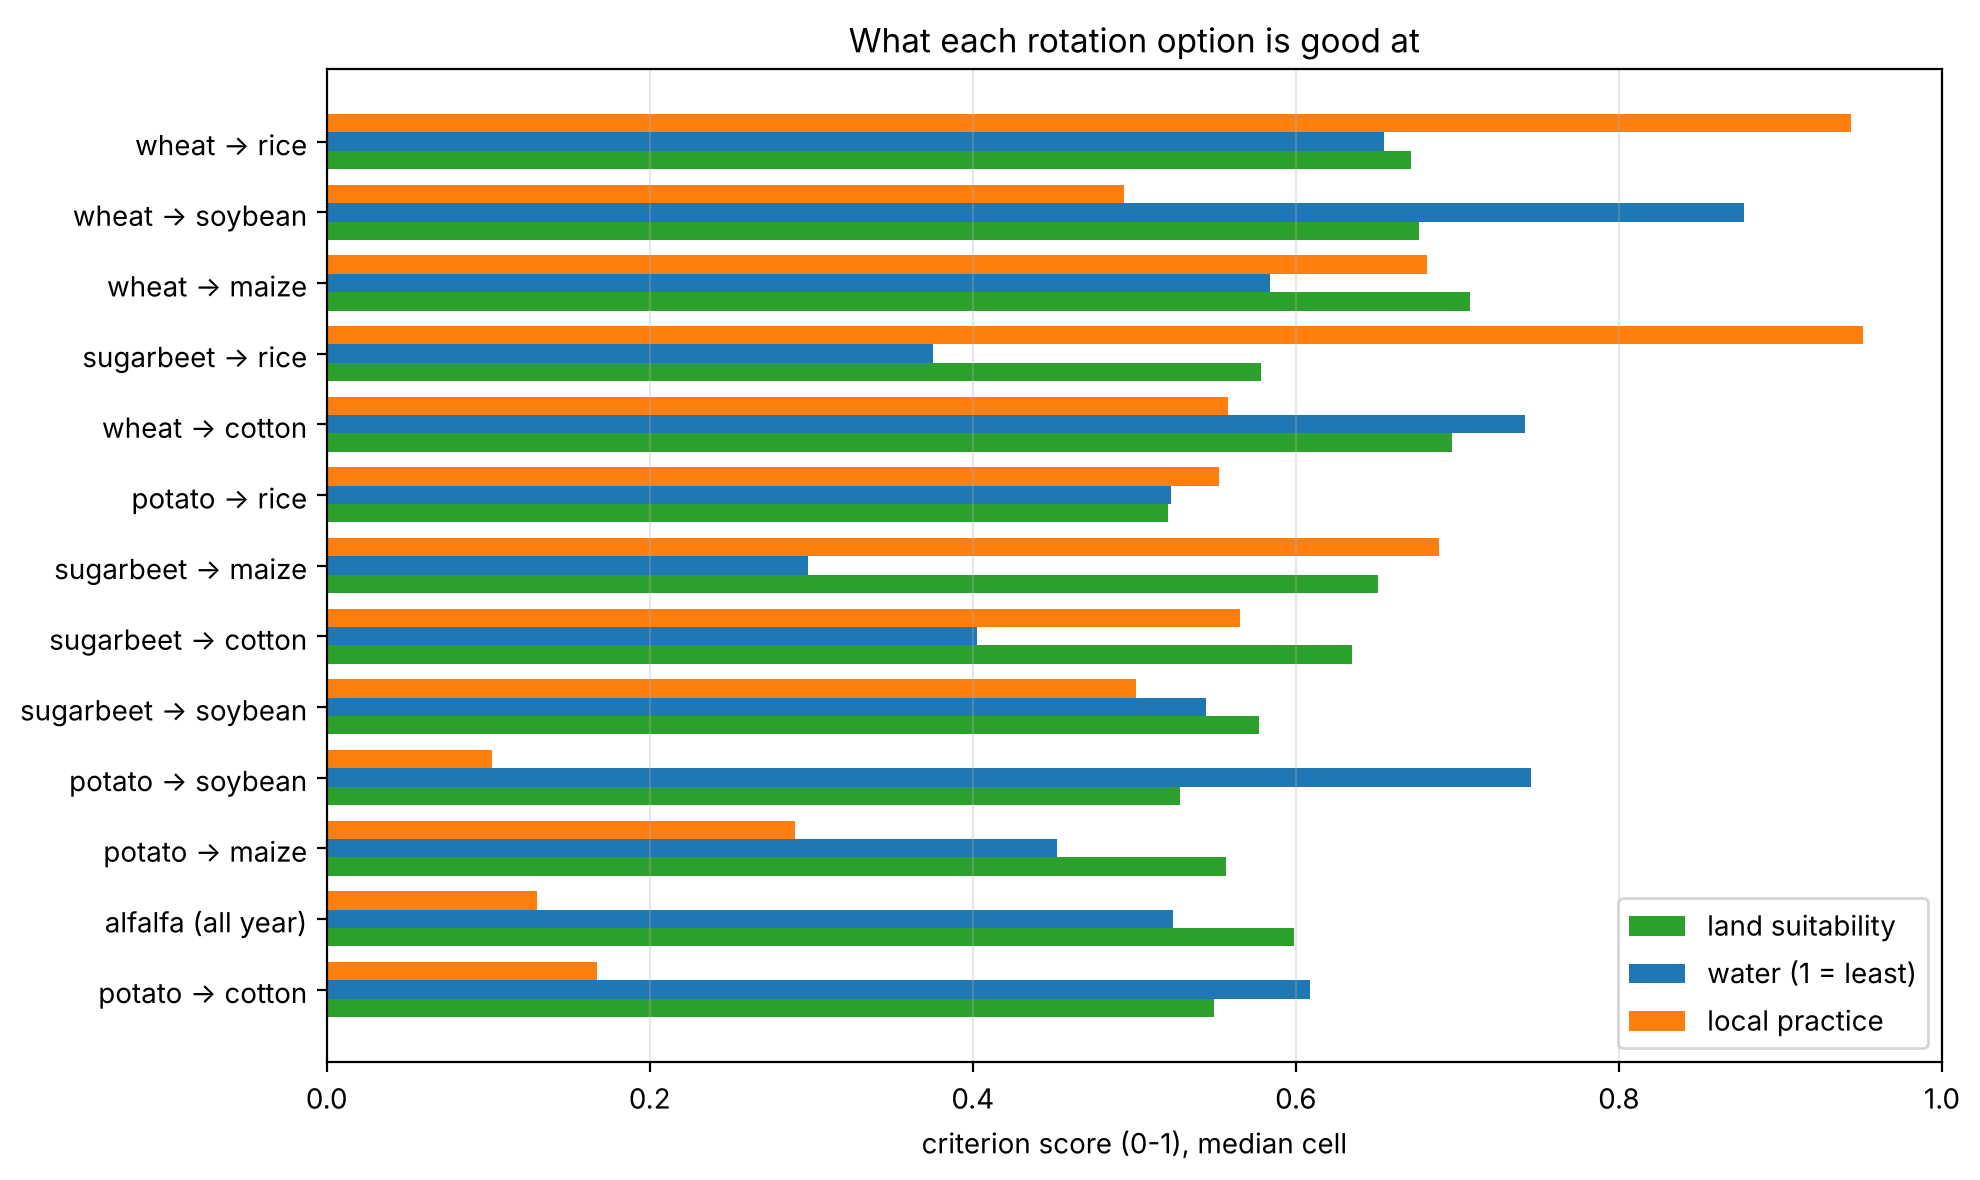

In [5]:
med = sc.groupby("option")[["s_land", "s_water", "s_practice"]].median()
med = med.loc[sc.groupby("option").score_fit.median().sort_values().index]
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(med)); h = 0.26
ax.barh(y - h, med.s_land,     h, label="land suitability", color="tab:green")
ax.barh(y,     med.s_water,    h, label="water (1 = least)", color="tab:blue")
ax.barh(y + h, med.s_practice, h, label="local practice",   color="tab:orange")
ax.set_yticks(y, med.index); ax.set_xlim(0, 1)
ax.set_xlabel("criterion score (0-1), median cell")
ax.set_title("What each rotation option is good at")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "11_criteria_by_option.png", dpi=150); plt.show()

## Step 4 - How much water would the shift save?

For each cell: irrigation of the **best fit today** minus irrigation of the **water-saving alternative**. One millimetre over one hectare is 10 cubic metres.

In [6]:
fit_top   = sc[sc.rank_fit == 1].set_index("cell_id").sort_index()
water_top = sc[sc.rank_water == 1].set_index("cell_id").sort_index()
saving_mm = fit_top.irrig_mm_year - water_top.irrig_mm_year
land_diff = water_top.suitability - fit_top.suitability

print(f"cells where the alternative differs from the best fit: {(fit_top.option != water_top.option).sum()} of 560")
print(f"water saving: median {saving_mm.median():.0f} mm/year = {saving_mm.median() * 10:,.0f} m3 per hectare per year")
print(f"              range {saving_mm.min():.0f} to {saving_mm.max():.0f} mm/year")
print(f"land suitability change: median {land_diff.median():+.1f} points (range {land_diff.min():+.1f} to {land_diff.max():+.1f})")

farm = mc.set_index("cell_id").farm_pct
total_m3 = (saving_mm * 10 * farm * 100).sum()          # 100 ha per cell, times its farmland share
print(f"\nif every farm hectare in the pilot area switched: about {total_m3 / 1e6:,.1f} million m3 per year")

cells where the alternative differs from the best fit: 560 of 560
water saving: median 173 mm/year = 1,730 m3 per hectare per year
              range 80 to 223 mm/year
land suitability change: median +0.7 points (range -13.2 to +2.8)

if every farm hectare in the pilot area switched: about 83.1 million m3 per year


That total is an illustration of scale, not a forecast: it assumes every field changes and uses GAEZ's net irrigation need, which (as noted above) understates rice's real water use. Because rice is the crop being replaced, the real saving would be **larger**, not smaller.

## Step 5 - Does the answer depend on the weights?

Equal weights are a choice. We repeat the ranking for **every combination of weights** from 0 to 1 in steps of 0.1 that adds up to 1 - 66 combinations, including extremes such as "land only" or "ignore practice". For each cell, **robustness** is the share of those 66 that give the same top option as equal weights. We measure it three ways: for the whole rotation, for the winter crop alone, and for the summer crop alone - because a rotation can be uncertain while one of its two halves is not.

In [7]:
grid = [(a / 10, b / 10, (10 - a - b) / 10) for a in range(11) for b in range(11 - a)]
base = fit_top.option
season_of = sc.drop_duplicates("option").set_index("option")
winter_of = season_of.winter_crop.fillna("alfalfa")            # alfalfa occupies both seasons
summer_of = season_of.summer_crop.fillna("alfalfa")
same, same_w, same_s = (pd.Series(0, index=base.index) for _ in range(3))
for wl, ww, wp in grid:
    t = sc.assign(_s=score(sc, wl, ww, wp)).loc[lambda d: d.groupby("cell_id")._s.idxmax()] \
          .set_index("cell_id").option.reindex(base.index)
    same   += (t == base).astype(int)
    same_w += (t.map(winter_of) == base.map(winter_of)).astype(int)
    same_s += (t.map(summer_of) == base.map(summer_of)).astype(int)
robust, robust_w, robust_s = same / len(grid), same_w / len(grid), same_s / len(grid)

print(f"weight combinations tested: {len(grid)}")
print(f"robustness of the whole rotation: median {robust.median():.2f}, lowest {robust.min():.2f}, highest {robust.max():.2f}")
print(f"robustness of the WINTER crop    : median {robust_w.median():.2f}, lowest {robust_w.min():.2f}")
print(f"robustness of the SUMMER crop    : median {robust_s.median():.2f}, lowest {robust_s.min():.2f}")

ext = {"land only": (1, 0, 0), "water only": (0, 1, 0), "practice only": (0, 0, 1),
       "land + water": (.5, .5, 0), "land + practice": (.5, 0, .5), "water + practice": (0, .5, .5), "equal": (1/3, 1/3, 1/3)}
print("\nmost common top option under different priorities:")
for k, (a, b, c) in ext.items():
    t = sc.assign(_s=score(sc, a, b, c)).loc[lambda d: d.groupby("cell_id")._s.idxmax()].option.value_counts()
    print(f"  {k:16s} -> {t.index[0]:22s} ({t.iloc[0]} cells)")

weight combinations tested: 66
robustness of the whole rotation: median 0.64, lowest 0.55, highest 0.73
robustness of the WINTER crop    : median 0.98, lowest 0.98
robustness of the SUMMER crop    : median 0.65, lowest 0.56

most common top option under different priorities:
  land only        -> wheat -> maize         (560 cells)
  water only       -> wheat -> soybean       (450 cells)
  practice only    -> sugarbeet -> rice      (560 cells)
  land + water     -> wheat -> soybean       (488 cells)
  land + practice  -> wheat -> rice          (560 cells)
  water + practice -> wheat -> rice          (560 cells)
  equal            -> wheat -> rice          (560 cells)


## Step 6 - Confidence and warnings for each cell

**Confidence** starts from robustness (high if the top option survives at least 80% of weight choices, medium from 50%, low below that) and drops one level if the cell needed a filled value.

**Warnings** carry everything that is the same for all options in a cell, so it could not change the ranking but the farmer should know:

| Warning | Trigger | From |
|---|---|---|
| not farmland | `is_farm_cell` is false | 08 |
| village growing | farmland share fell more than 10 points since 1985-94 | 08 |
| crops weakening | Landsat trend declining with farmland intact | 08 |
| saline on soil map | GAEZ names salinity as the main soil limit | 06b |
| filled value | GAEZ had no value here for a crop in the option | 06, 09 |

In [8]:
cell = mc.set_index("cell_id")
level = pd.Series(np.where(robust >= 0.8, 2, np.where(robust >= 0.5, 1, 0)), index=robust.index)
filled = fit_top.suit_filled | fit_top.water_filled
level = (level - filled.astype(int)).clip(lower=0)
conf = level.map({2: "high", 1: "medium", 0: "low"})
conf[~cell.is_farm_cell] = "none"

warn = pd.Series([[] for _ in range(len(cell))], index=cell.index)
village = cell.ls_farm_pct_change < -0.10
weakening = (cell.ls_trend_class == "declining") & ~village
saline = cell.soil_limit_name == "salinity and sodicity"
for cid in cell.index:
    w = []
    if not cell.at[cid, "is_farm_cell"]: w.append("mostly not farmland - no crop recommendation")
    if village[cid]:   w.append("the village is growing into the fields here (Landsat, since 1985)")
    if weakening[cid]: w.append("crop vigour has declined for 40 years on intact farmland - check soil and water before a demanding crop")
    if saline[cid]:    w.append("the soil map marks this area as saline, though crops here look as healthy as elsewhere - a soil test is advised")
    if filled[cid]:    w.append("FAO had no value here for one of the crops; the area average was used")
    warn[cid] = w

print("confidence:", conf.value_counts().to_dict())
print(f"warnings: not farmland {(~cell.is_farm_cell).sum()}, village growing {village.sum()}, "
      f"crops weakening {weakening.sum()} {cell.index[weakening].tolist()}, saline {saline.sum()}, filled {filled.sum()}")

confidence: {'medium': 504, 'low': 52, 'none': 4}
warnings: not farmland 4, village growing 21, crops weakening 1 [501], saline 47, filled 52


## Step 7 - Plain-language reasons

Every recommendation carries one sentence a farmer can read, built only from the numbers above.

In [9]:
def pretty(c): return {"sugarbeet": "sugar beet"}.get(c, c)

def reason(r):
    crops = [r.winter_crop, r.summer_crop] if r.summer_crop else ["alfalfa"]
    head = " then ".join(pretty(c) for c in crops)
    head = head[0].upper() + head[1:]
    grown = "; ".join(
        f"{pretty(c)} {share[c]:.1f}% of the 2020 harvest" if share[c] >= 1
        else f"{pretty(c)} is rarely grown here ({share[c]:.2f}% of the 2020 harvest)"
        for c in crops)
    txt = (f"{head}: land suitability {r.suitability:.0f}/100, irrigation about "
           f"{r.irrig_mm_year:,.0f} mm a year; {grown}.")
    if r.has_sugarbeet: txt += " Sugar beet is scored as a winter crop; its land score uses the summer crop only."
    if r.has_rice:      txt += " Flooded rice also loses water by seepage, so its real water use is higher than shown."
    return txt

sc["reason"] = sc.apply(reason, axis=1)

rec = mc[["cell_id", "row", "col", "lat", "lon", "farm_pct", "is_farm_cell"]].set_index("cell_id")
for k in [1, 2, 3]:
    t = sc[sc.rank_fit == k].set_index("cell_id").sort_index()
    rec[f"top{k}_option"], rec[f"top{k}_score"], rec[f"top{k}_reason"] = t.option, t.score_fit.round(3), t.reason
alt = sc[sc.rank_water == 1].set_index("cell_id").sort_index()   # rebuilt: now carries the reason column
rec["water_alt_option"]  = alt.option
rec["water_alt_saving_mm"]  = saving_mm.round(0)
rec["water_alt_saving_m3_ha"] = (saving_mm * 10).round(0)
rec["water_alt_reason"]  = alt.reason
rec["robustness"] = robust.round(2)
rec["winter_robustness"] = robust_w.round(2)
rec["summer_robustness"] = robust_s.round(2)
rec["confidence"] = conf
rec["warnings"]   = warn.apply(lambda w: " | ".join(w))
rec.loc[~rec.is_farm_cell, [c for c in rec.columns if c.startswith(("top", "water_alt"))]] = None
rec = rec.reset_index()

ex = rec[rec.is_farm_cell].iloc[0]
print(f"example, cell {ex.cell_id} (confidence {ex.confidence}):")
for k in [1, 2, 3]: print(f"  {k}. {ex[f'top{k}_reason']}")
print(f"  water-saving alternative: {ex.water_alt_reason} Saves about {ex.water_alt_saving_m3_ha:,.0f} m3 per hectare per year.")
print(f"  warnings: {ex.warnings or 'none'}")

example, cell 1 (confidence medium):
  1. Wheat then rice: land suitability 88/100, irrigation about 1,040 mm a year; wheat 19.6% of the 2020 harvest; rice 17.9% of the 2020 harvest. Flooded rice also loses water by seepage, so its real water use is higher than shown.
  2. Wheat then soybean: land suitability 77/100, irrigation about 838 mm a year; wheat 19.6% of the 2020 harvest; soybean is rarely grown here (0.04% of the 2020 harvest).
  3. Wheat then maize: land suitability 89/100, irrigation about 1,084 mm a year; wheat 19.6% of the 2020 harvest; maize 7.5% of the 2020 harvest.
  water-saving alternative: Wheat then soybean: land suitability 77/100, irrigation about 838 mm a year; wheat 19.6% of the 2020 harvest; soybean is rarely grown here (0.04% of the 2020 harvest). Saves about 2,020 m3 per hectare per year.
  warnings: none


## Step 8 - Maps

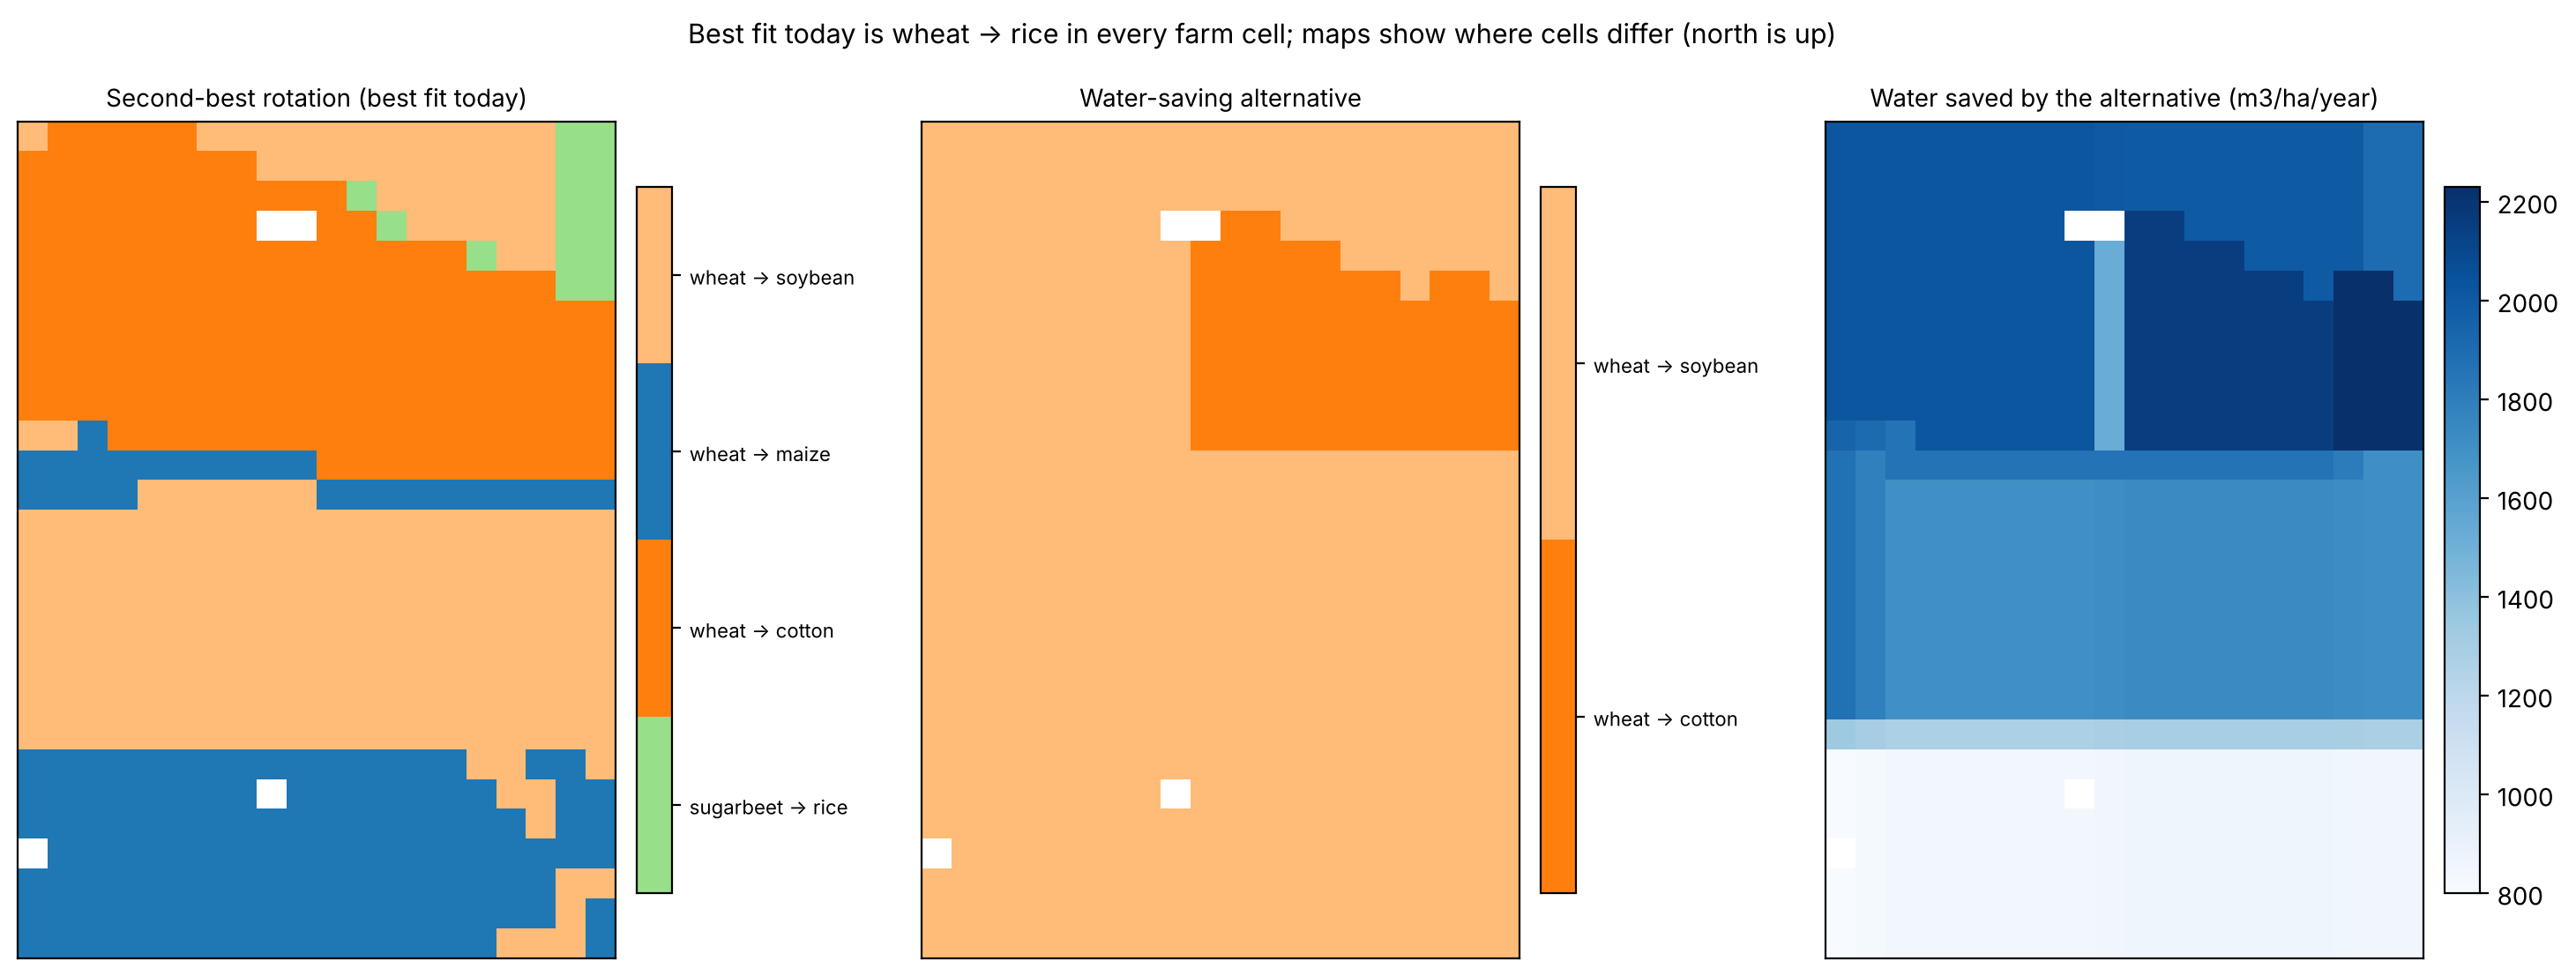

In [10]:
from matplotlib.colors import ListedColormap
NR, NC = mc.row.max(), mc.col.max()
def to_map(series):
    a = np.full((NR, NC), np.nan)
    g = cell.loc[series.index]
    a[g.row.values - 1, g.col.values - 1] = series.values
    return a

# one fixed colour per option, the same in every map
ALL_OPTS = [NAME(w, s) for w, s in OPTIONS]
COLOR = {o: plt.cm.tab20.colors[i % 20] for i, o in enumerate(ALL_OPTS)}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.6))
for ax, (col, title) in zip(axes[:2], [("top2_option", "Second-best rotation (best fit today)"),
                                       ("water_alt_option", "Water-saving alternative")]):
    s = rec.set_index("cell_id")[col]
    cats = sorted(s.dropna().unique())
    im = ax.imshow(to_map(s.map({c: i for i, c in enumerate(cats)})),
                   cmap=ListedColormap([COLOR[c] for c in cats]), vmin=-0.5, vmax=len(cats) - 0.5)
    cb = plt.colorbar(im, ax=ax, ticks=range(len(cats)), fraction=0.05, pad=0.03); cb.ax.set_yticklabels(cats, fontsize=8)
    ax.set_title(title, fontsize=10)
s = rec.set_index("cell_id").water_alt_saving_m3_ha
im = axes[2].imshow(to_map(s), cmap="Blues"); plt.colorbar(im, ax=axes[2], fraction=0.05, pad=0.03)
axes[2].set_title("Water saved by the alternative (m3/ha/year)", fontsize=10)
for a in axes: a.set_xticks([]); a.set_yticks([])
fig.suptitle(f"Best fit today is {fit_top.option.mode()[0]} in every farm cell; maps show where cells differ (north is up)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "11_recommendation_maps.png", dpi=150); plt.show()

## Step 9 - Save

In [11]:
out_cols = ["cell_id", "option", "winter_crop", "summer_crop", "suitability", "irrig_mm_year", "practice_pct",
            "s_land", "s_water", "s_practice", "score_fit", "score_water", "rank_fit", "rank_water",
            "suit_filled", "water_filled", "reason"]
checks = {
    "scores_all: 7,280 rows, unique cell-option":   len(sc) == 7280 and not sc.duplicated(["cell_id", "option"]).any(),
    "every criterion inside 0-1":                   sc[["s_land", "s_water", "s_practice"]].stack().between(0, 1).all(),
    "every cell has ranks 1-13 exactly once":       (sc.groupby("cell_id").rank_fit.apply(lambda r: sorted(r) == list(range(1, 14)))).all(),
    "recommendations: 560 rows":                    len(rec) == 560 and rec.cell_id.is_unique,
    "every farm cell has 3 options and a reason":   rec[rec.is_farm_cell][["top1_option", "top2_option", "top3_option", "top1_reason"]].notna().all().all(),
    "non-farm cells have no recommendation":        rec[~rec.is_farm_cell].top1_option.isna().all(),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values())

sc[out_cols].to_csv(P / "scores_all.csv", index=False)
rec.to_csv(P / "recommendations.csv", index=False)
for f in ["scores_all.csv", "recommendations.csv"]:
    print(f"saved {f:22s} {pd.read_csv(P / f).shape}")

  PASS  scores_all: 7,280 rows, unique cell-option
  PASS  every criterion inside 0-1
  PASS  every cell has ranks 1-13 exactly once
  PASS  recommendations: 560 rows
  PASS  every farm cell has 3 options and a reason
  PASS  non-farm cells have no recommendation
saved scores_all.csv         (7280, 17)
saved recommendations.csv    (560, 25)


## Conclusion

The scoring ran on `master_cell.csv` alone, every check passed, and every number below comes from the outputs above. Each of the 556 farm cells now has three ranked rotations, a water-saving alternative, a confidence level, warnings, and a plain-language reason for each choice.

### 1. The three criteria point to three different rotations

| Priority | Best rotation (most cells) |
|---|---|
| Land suitability only | wheat -> maize (560 cells) |
| Water only | wheat -> soybean (450) |
| Local practice only | sugar beet -> rice (560) |
| **All three, equal weight** | **wheat -> rice (560)** |

There is no single "best" rotation independent of what the farmer values. That is the most important result of this notebook, and the tool says it openly instead of hiding it behind one number.

### 2. Winter is certain, summer is a choice

Across all 66 weight combinations, the best **winter** crop stays the same in **98%** of them (median cell): **wheat**. The best **summer** crop stays the same in only **65%**. The whole rotation stays the same in a median **64%** (range 55-73%), which is why most cells get **medium** confidence (504 cells), and cells that needed a filled-in GAEZ value get **low** (52 cells).

So the honest recommendation is: *winter: wheat, with high confidence; summer: depends on whether you put land, water or what your neighbours grow first.*

### 3. Best fit today: wheat -> rice

With equal weights, wheat -> rice is first in every cell. It wins mainly on local practice (score 0.944 against 0.494 for the next option): wheat and rice are among the most harvested crops here. On land suitability (0.671) and water (0.655) it is only middle of the pack. In other words, **the best fit today is close to what farmers already do** - which is reassuring for the data, but not a change.

The second choice varies across the map: wheat -> soybean (216 cells), wheat -> cotton (176), wheat -> maize (153), sugar beet -> rice (15).

### 4. The Field Shift: wheat -> soybean saves water without losing land quality

On land and water alone, the best rotation is **wheat -> soybean in 488 cells** and **wheat -> cotton in 72**. Compared with today's best fit it saves a median **173 mm of irrigation a year - about 1,730 m³ per hectare** (range 80-223 mm), with a median change in land suitability of only **+0.7 points**.

If every farm hectare in the pilot area switched, that would be roughly **83 million m³ a year**. This is a scale illustration, not a forecast, and it is **conservative**: GAEZ's water number counts only what crops consume, while the crop being replaced, flooded rice, also loses water through seepage.

The catch is stated in the tool itself: soybean is **rarely grown here today (0.04% of the 2020 harvest)**. A water-saving shift is only real if the market and know-how for the new crop exist - something no satellite can measure.

### 5. Warnings carried to the user

| Warning | Cells |
|---|---|
| Mostly not farmland - no recommendation | 4 |
| Village growing into the fields | 21 |
| Crop vigour declining on intact farmland (cell 501) | 1 |
| Saline on the soil map | 47 |
| A GAEZ value was filled with the area average | 52 |

### Limits we state openly

- **Spatial detail follows the coarse layers.** Differences between cells come mostly from GAEZ (~10 km irrigation pixels, soil-map blocks), so the maps change in blocks, not field by field.
- **No profit and no agronomic rotation rules** (such as legume benefits): neither is in the NASA and FAO resources we committed to.
- **Rice water use is underestimated** by GAEZ, which favours rice in every view where water counts.

### Hand-off

| File | Shape | For |
|---|---|---|
| `recommendations.csv` | 560 x 25 | the website: one row per cell, ready to display |
| `scores_all.csv` | 7,280 x 17 | full transparency: every option, every criterion, every score |